# Summary across all 10 sources

Collect every folder's results.csv -> ALL_RESULTS.csv, README.md (master) and a README.md per folder.
Run after the folder notebooks (datasets/<folder>/<folder>.ipynb).

Writes `datasets/ALL_RESULTS.csv`, `datasets/README.md` and each folder's `README.md`.

In [1]:
# Setup: run from the repository root and load the shared protocol (datasets/common/*.ipynb)
import os, sys, warnings
os.environ['PYTHONWARNINGS'] = 'ignore'; warnings.filterwarnings('ignore')
while not os.path.isdir('datasets') and os.path.dirname(os.getcwd()) != os.getcwd():
    os.chdir('..')
sys.path.insert(0, 'scripts')          # curated loaders: scripts/external_datasets.py, us_datasets.py, europe_datasets.py
import pandas as pd
pd.set_option('display.max_colwidth', 60); pd.set_option('display.width', 200)
HERE = 'datasets/'
print('working directory:', os.getcwd())

working directory: /home/claude/toxo


In [2]:
import glob, json, os
import pandas as pd
HERE = 'datasets'
H = os.path.join(HERE, '_harvest')
INFO = {
    '01_nhanes': ('CDC NHANES (U.S. National Health and Nutrition Examination Survey)',
                  'Public, de-identified survey files from CDC/NCHS (wwwn.cdc.gov/nchs/nhanes), downloaded as .XPT by the build scripts. '
                  'Four Toxoplasma cohorts with three different assays, so they are evaluated separately, never pooled across assays. '
                  'New in this folder: NHANES 1999-2004 (files LAB17, L17_B, L17_C; IgG tested at ages 6-49).',
                  None),
    '02_plos': ('PLOS journals (PLOS ONE, PLOS Neglected Tropical Diseases, PLOS Global Public Health)',
                'Participant-level supplementary files (PLOS requires underlying data). Found through the Europe PMC search below and '
                'downloaded from the PMC Open Access S3 bucket.', None),
    '03_bmc_springer_nature': ('BMC / Springer Nature journals (BMC Infectious Diseases, Parasites & Vectors, ...)',
                               'Participant-level supplementary files ("MOESM"), found through Europe PMC; Springer Nature also mirrors them on Figshare.', None),
    '04_peerj': ('PeerJ', 'PeerJ publishes the raw data of every article as supplementary files; found through Europe PMC.', None),
    '05_mendeley_data': ('Mendeley Data (Elsevier data repository)',
                         'Searched with the public API (data.mendeley.com/api/research-data/search, 76 Toxoplasma records); '
                         'files downloaded through public-api links. MDPI journals were also checked and had no usable participant-level data.', None),
    '06_other_journals': ('Other journals (ASTMH, Frontiers, Elsevier Heliyon, Wiley/Hindawi)',
                          'Publishers that contribute one or two datasets each; found through Europe PMC.', None),
    '07_figshare': ('Figshare', 'Datasets deposited directly by authors (2,286 search hits; journal mirrors are filed under their journal). '
                    'Most usable ones come from the Flegr lab, Charles University, Prague.', None),
    '08_zenodo': ('Zenodo (CERN)', 'Zenodo API search (2,136 Toxoplasma records, 25 per page); Dryad mirrors are filed under 09_dryad.', None),
    '09_dryad': ('Dryad', 'Dryad API search (38 Toxoplasma records, almost all animal or laboratory); files from the Zenodo mirror.', None),
    '10_harvard_dataverse': ('Harvard Dataverse', 'Dataverse search API (175 hits); NHANES copies hosted by ICPSR excluded (they belong to 01_nhanes).', None),
}
SEARCH = ('**How the journal datasets were found.** Europe PMC was searched for every open-access paper with supplementary files whose '
          'title/abstract mentions Toxoplasma, toxoplasmosis, gondii, TORCH, multiplex serology or pathogen burden (3,482 papers). '
          'Their data files (xlsx, xls, csv, sav, dta, ...) were downloaded from the PMC Open Access S3 bucket (1,407 papers had data '
          'files, 6.6 GB) and every table with >= 80 rows was scanned for a Toxoplasma result column (607 tables, 285 papers). '
          'Human, participant-level tables with at least two IgG classes were then checked by hand. Scripts: `datasets/_harvest/`.')
RULES = ('**Same protocol for every dataset** (`datasets/common/protocol.py`): label = Toxoplasma IgG positive; every column that '
         'measures Toxoplasma itself (IgM, avidity, titre, OD, PCR, other kits) and identifiers are removed; logistic regression, '
         'random forest and XGBoost; ROC-AUC from 5-fold x 3 repeated stratified cross-validation with preprocessing inside the folds. '
         'Datasets with fewer than 20 positives or 20 negatives are catalogued but not evaluated.')

**`table`**

In [3]:
def table(df, cols=('dataset', 'country', 'setting', 'n', 'positives', 'n_features', 'LogReg_auc', 'RandomForest_auc', 'XGBoost_auc', 'best_auc')):
    head = ['dataset', 'country', 'setting', 'n', 'pos', 'features', 'LogReg', 'RF', 'XGBoost', 'best']
    lines = ['| ' + ' | '.join(head) + ' |', '|' + '---|' * len(head)]
    for _, r in df.iterrows():
        v = ['' if pd.isna(r.get(c)) else (f'{r[c]:.3f}' if isinstance(r.get(c), float) and 'auc' in c else str(r.get(c))) for c in cols]
        v = [x.replace('.0', '') if c in ('n', 'positives', 'n_features') else x for x, c in zip(v, cols)]
        if v[-1]:
            v[-1] = f'**{v[-1]}**'
        lines.append('| ' + ' | '.join(v) + ' |')
    return '\n'.join(lines)

In [4]:
allr = []
for folder in sorted(INFO):
    p = os.path.join(HERE, folder, 'results.csv')
    if not os.path.exists(p):
        continue
    r = pd.read_csv(p); r.insert(0, 'source', folder)
    if folder == '01_nhanes':
        r['country'] = 'USA'; r['setting'] = r['description']
    allr.append(r)
    name, how, cmd = INFO[folder]
    notes = '\n'.join(f'- **{x.dataset}** ({x.doi if isinstance(x.get("doi"), str) else ""}): {x.title if isinstance(x.get("title"), str) else ""}'
                      + (f' — {x.note}' if isinstance(x.get('note'), str) and x.note else '') for _, x in r.iterrows()) if folder != '01_nhanes' else \
        '\n'.join(f'- **{x.dataset}**: {x.description}' for _, x in r.iterrows())
    md = (f'# {folder}: {name}\n\n{how}\n\n' + (SEARCH + '\n\n' if folder in ('02_plos', '03_bmc_springer_nature', '04_peerj', '06_other_journals') else '')
          + f'## Results (ROC-AUC, 5-fold x 3 CV)\n\n{table(r)}\n\n## Datasets\n\n{notes}\n\n{RULES}\n\n'
          f'## Run\n\nOpen `{folder}.ipynb` (in this folder) in Jupyter / VS Code and run all cells, or from the repository root:\n'
          f'`jupyter nbconvert --to notebook --execute --inplace datasets/{folder}/{folder}.ipynb`\n\n'
          f'Folder layout: `{folder}.ipynb` (one section per dataset: where it comes from, how the label is coded, what is removed; then the '
          'evaluation and a chart), `raw/` (original files), '
          '`processed/<dataset>.csv` (model-ready inputs + `target_toxo_pos`), `results.csv`.\n'
          'Cite the original paper / repository DOI when using a dataset.\n')
    open(os.path.join(HERE, folder, 'README.md'), 'w').write(md)
A = pd.concat(allr, ignore_index=True)
A.to_csv(os.path.join(HERE, 'ALL_RESULTS.csv'), index=False)
ev = A[A.best_auc.notna()].sort_values('best_auc', ascending=False)
per = A.groupby('source').agg(datasets=('dataset', 'size'), evaluated=('best_auc', lambda s: s.notna().sum()),
                              people=('n', 'sum'), positives=('positives', 'sum'), best=('best_auc', 'max')).reset_index()
src_lines = ['| folder | source | datasets | evaluated | people | positives | best ROC-AUC |', '|---|---|---|---|---|---|---|']
for _, r in per.iterrows():
    src_lines.append(f'| `{r.source}` | {INFO[r.source][0]} | {r.datasets} | {r.evaluated} | {int(r.people):,} | {int(r.positives):,} | {r.best:.3f} |')
md = ('# Toxoplasma datasets by source\n\n'
      f'{len(A)} human, participant-level Toxoplasma IgG datasets from 10 sources ({int(A.n.sum()):,} people, '
      f'{int(A.positives.sum()):,} seropositive); {len(ev)} have enough cases to evaluate. One folder per source; '
      'every folder uses the same evaluation protocol, so ROC-AUCs are comparable. (People counts for NHANES overlap: '
      'the 2009-2014 pooled cohort contains the 2013-2014 adults; without the overlap the total is '
      f'{int(A.n.sum()) - 5006:,} people.)\n\n'
      '## Sources\n\n' + '\n'.join(src_lines) + '\n\n'
      '## Every evaluated dataset, best first\n\n' + table(ev.assign(dataset=ev.source.str[:2] + '/' + ev.dataset)) + '\n\n'
      + RULES + '\n\n' + SEARCH + '\n\n'
      '**Reading the numbers.** These are within-dataset cross-validated scores. Small datasets (n < 300) have wide '
      'uncertainty (SD 0.05-0.10, see each results.csv); datasets whose inputs are personality or cognitive scores measure '
      'possible consequences of infection rather than exposures; case-control studies can score high because the case '
      'group itself differs in prevalence.\n\n'
      '## Notebooks\n\n- `00_summary.ipynb`: this table + charts across all sources\n'
      '- `visualizations.ipynb`: all charts in one notebook (also saved as PNGs in `figures/`)\n'
      '- `<folder>/<folder>.ipynb`: one per source (01 also builds NHANES 1999-2004)\n'
      '- `common/protocol.ipynb`, `common/folder_tools.ipynb`: the shared evaluation protocol and dataset builder\n'
      '- `_harvest/harvest.ipynb`: how the datasets were found (searches, downloads, table scan)\n\n'
      'Run everything from the repository root:\n\n```\n'
      'for nb in datasets/[0-9]*_*/[0-9]*.ipynb datasets/00_summary.ipynb; do jupyter nbconvert --to notebook --execute --inplace $nb; done\n```\n')
open(os.path.join(HERE, 'README.md'), 'w').write(md)

print(per.to_string(index=False)); print(len(A), 'datasets,', len(ev), 'evaluated')

                source  datasets  evaluated  people  positives  best
             01_nhanes         4          4   43664       8743 0.742
               02_plos        14         13   10002       2527 0.865
03_bmc_springer_nature         3          2    1360        228 0.632
              04_peerj         2          2    1598        148 0.892
      05_mendeley_data         4          3    1119        247 0.670
     06_other_journals         4          4     680        303 0.702
           07_figshare         7          7    5697       1458 0.659
             08_zenodo         3          3    3806       1355 0.784
              09_dryad         2          1    1490        343 0.571
  10_harvard_dataverse         1          1     300        150 0.672
44 datasets, 40 evaluated


## Per-source totals

In [5]:
per

,source,datasets,evaluated,people,positives,best
0,01_nhanes,4,4,43664,8743,0.742
1,02_plos,14,13,10002,2527,0.865
2,03_bmc_springer_nature,3,2,1360,228,0.632
3,04_peerj,2,2,1598,148,0.892
4,05_mendeley_data,4,3,1119,247,0.670
5,06_other_journals,4,4,680,303,0.702
6,07_figshare,7,7,5697,1458,0.659
7,08_zenodo,3,3,3806,1355,0.784
8,09_dryad,2,1,1490,343,0.571
9,10_harvard_dataverse,1,1,300,150,0.672


## Charts

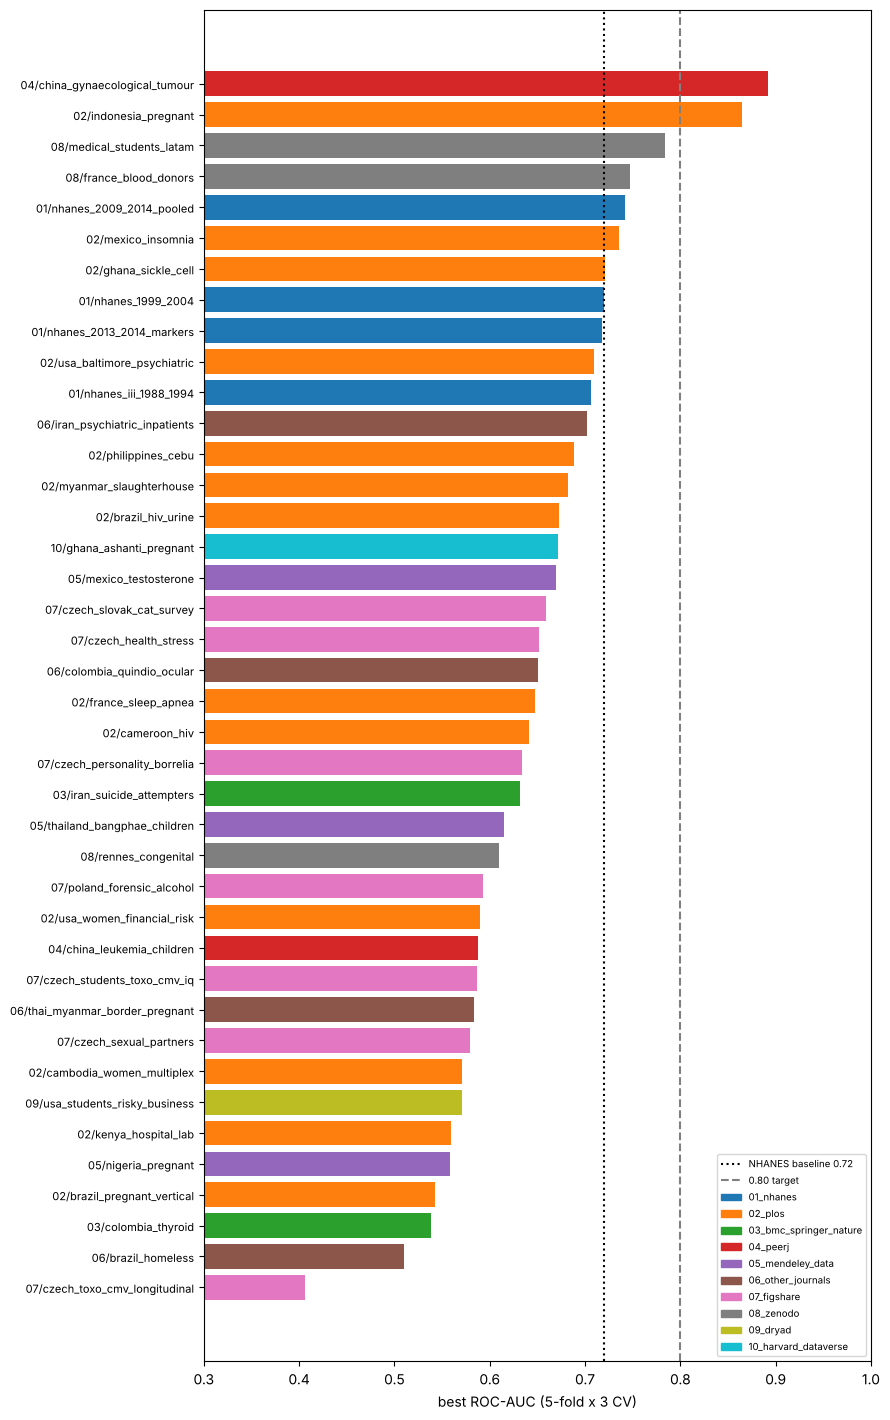

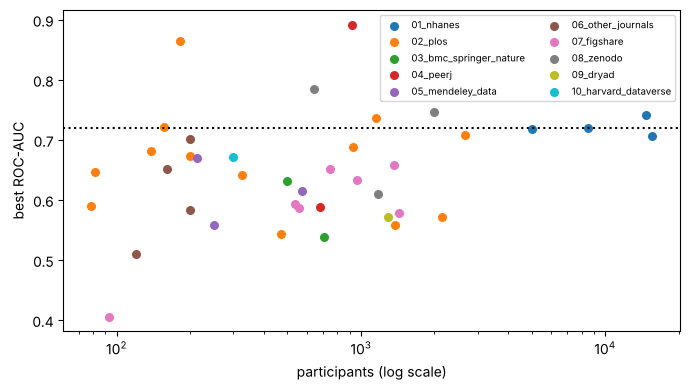

In [6]:
# Every evaluated dataset, coloured by source
import matplotlib.pyplot as plt
ev = A[A.best_auc.notna()].sort_values('best_auc')
src = sorted(ev.source.unique()); cmap = plt.get_cmap('tab10')
fig, ax = plt.subplots(figsize=(9, 0.32 * len(ev) + 1.5))
ax.barh(range(len(ev)), ev.best_auc, color=[cmap(src.index(s)) for s in ev.source])
ax.set_yticks(range(len(ev))); ax.set_yticklabels(ev.source.str[:2] + '/' + ev.dataset, fontsize=8)
ax.axvline(0.72, ls=':', color='black', label='NHANES baseline 0.72'); ax.axvline(0.8, ls='--', color='grey', label='0.80 target')
from matplotlib.patches import Patch
handles = [Patch(color=cmap(src.index(s)), label=s) for s in src]
ax.set_xlim(0.3, 1.0); ax.set_xlabel('best ROC-AUC (5-fold x 3 CV)')
ax.legend(handles=ax.get_legend_handles_labels()[0] + handles, fontsize=7, loc='lower right')
plt.tight_layout(); plt.show()

# Size vs score: small datasets scatter widely
fig, ax = plt.subplots(figsize=(7, 4))
for s in src:
    e = ev[ev.source == s]; ax.scatter(e.n, e.best_auc, color=cmap(src.index(s)), label=s, s=30)
ax.set_xscale('log'); ax.set_xlabel('participants (log scale)'); ax.set_ylabel('best ROC-AUC'); ax.axhline(0.72, ls=':', color='black')
ax.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.show()